# 02 | Recursive Operational Benchmark

## Purpose

This notebook documents the project's simple seasonal forecasting benchmark. The benchmark provides a transparent reference against which the later SARIMA and CNY-aware models can be judged.

For each future calendar month, the method forecasts published month-on-month inflation using the average rate observed in that same calendar month over the preceding five years. These monthly forecasts are compounded recursively into an index path and then converted into year-on-year inflation forecasts.

The notebook uses one illustrative forecast origin, **December 2020**, to verify the benchmark's mechanics over a 24-month horizon. It checks both the first forecast year, which uses only observed inputs, and the second forecast year, in which the rolling five-year window begins to include earlier benchmark forecasts.

> **Scope:** The MAE and RMSE calculated here describe this single illustrative forecast path only. They are not the project's final performance estimates. The final expanding-window comparison across all forecast origins is carried out in the later evaluation notebook.

## 1. Reproducible setup

The notebook is designed to run from the repository's `notebooks/` directory. Project functions are imported from `src/` so the benchmark logic is defined and tested once rather than reimplemented inside the notebook.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
if not (PROJECT_ROOT / "src").exists():
    raise RuntimeError(
        "Run this notebook from the repository's notebooks/ directory."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_ceic import load_cpi_series
from src.features.reconstruct_index import add_reconstructed_indices
from src.models.operational_benchmark import (
    forecast_operational_benchmark,
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "china_cpi.csv"

print("Working directory: notebooks/")
print("Project root: repository root")
print("Python environment: project virtual environment")
print("Licensed data file found:", DATA_PATH.exists())

Working directory: notebooks/
Project root: repository root
Python environment: project virtual environment
Licensed data file found: True


## 2. Load the CPI series and reconstructed index paths

The benchmark forecasts published month-on-month inflation, but a month-on-month forecast sequence must be compounded into a price-index path before a year-on-year forecast can be calculated. The reconstruction function therefore supplies the historical index levels needed at the forecast origin.

The licensed CEIC extract remains local and outside version control.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "The licensed CEIC extract is not available at the documented local path. "
        "Follow the README access instructions and keep the file outside version control."
    )

cpi = load_cpi_series(DATA_PATH)
cpi = add_reconstructed_indices(cpi)
cpi = cpi.asfreq("MS")

required_columns = [
    "headline_mom_published",
    "headline_yoy_published",
    "headline_index_reconstructed",
]

assert cpi.index.is_monotonic_increasing
assert cpi.index.is_unique
assert cpi[required_columns].notna().loc["2006-01-01":].all().all()

print("Data shape:", cpi.shape)
print("Data endpoint:", cpi.index.max().date())
display(cpi[required_columns].tail())

Data shape: (500, 10)
Data endpoint: 2026-08-01


,headline_mom_published,headline_yoy_published,headline_index_reconstructed
date,,,
2026-04-01,0.3,1.2,177.527703
2026-05-01,-0.1,1.2,177.350175
2026-06-01,-0.3,1.0,176.818125
2026-07-01,-0.1,0.5,176.641307
2026-08-01,0.4,0.8,177.347872


## 3. Benchmark definition

Let $m_t$ denote the published month-on-month inflation rate for target month $t$. With a five-year seasonal window, the benchmark forecast is

$$
\widehat{m}_{t\mid T}
=
\frac{1}{5}
\sum_{j=1}^{5} m^{*}_{t-12j},
$$

where $T$ is the forecast origin and $m^{*}_{t-12j}$ is the same-calendar-month input available to the recursive procedure.

- If $t-12j \leq T$, the input is an observed published month-on-month rate.
- If $t-12j > T$, the input is an earlier benchmark forecast generated within the same forecast path.

The monthly forecast is compounded recursively from the reconstructed index level at the origin:

$$
\widehat{P}_{T+h\mid T}
=
\widehat{P}_{T+h-1\mid T}
\left(1+\frac{\widehat{m}_{T+h\mid T}}{100}\right).
$$

The corresponding year-on-year forecast is

$$
\widehat{\pi}^{\mathrm{YoY}}_{T+h\mid T}
=
100\left(
\frac{\widehat{P}_{T+h\mid T}}
{P^{*}_{T+h-12\mid T}}
-1
\right),
$$

where the denominator is an observed reconstructed index level when the comparison month precedes the origin and an earlier forecast index level when it falls within the forecast path.

This recursive design makes the benchmark operational at every horizon without using information that was unavailable at the forecast origin.

## 4. Generate an illustrative 24-month headline forecast

The origin is fixed at December 2020. The estimation information set therefore ends in December 2020, and the first target is January 2021. The 24-month horizon extends through December 2022.

The five-year same-month window is deliberately fixed by the project function. This demonstration is intended to validate the mechanics, not to tune the benchmark after observing its outcomes.

In [3]:
FORECAST_ORIGIN = pd.Timestamp("2020-12-01")
FORECAST_HORIZON = 24
WINDOW_YEARS = 5

headline_sample = cpi.loc["2006-01-01":].dropna(
    subset=[
        "headline_mom_published",
        "headline_index_reconstructed",
    ]
)

assert FORECAST_ORIGIN in headline_sample.index
assert FORECAST_ORIGIN < headline_sample.index.max()

headline_result = forecast_operational_benchmark(
    monthly_rate=headline_sample["headline_mom_published"],
    index_level=headline_sample["headline_index_reconstructed"],
    forecast_origin=FORECAST_ORIGIN,
    horizon=FORECAST_HORIZON,
    window_years=WINDOW_YEARS,
)

headline_path = headline_result.forecast.copy()
headline_audit = headline_result.audit.copy()

assert len(headline_path) == FORECAST_HORIZON
assert headline_path["horizon"].tolist() == list(
    range(1, FORECAST_HORIZON + 1)
)
assert headline_path["target_date"].min() == pd.Timestamp("2021-01-01")
assert headline_path["target_date"].max() == pd.Timestamp("2022-12-01")
assert headline_path.notna().all().all()

print("Forecast origin:", FORECAST_ORIGIN.date())
print("Targets:", headline_path["target_date"].min().date(), "to", headline_path["target_date"].max().date())
print("Forecast rows:", len(headline_path))
display(headline_path)

Forecast origin: 2020-12-01
Targets: 2021-01-01 to 2022-12-01
Forecast rows: 24


,forecast_origin,target_date,horizon,mom_forecast,index_forecast,yoy_forecast
0,2020-12-01,2021-01-01,1,0.800,171.167791,-0.427537
1,2020-12-01,2021-02-01,2,0.880,172.674067,-0.348511
2,2020-12-01,2021-03-01,3,-0.680,171.499884,0.175971
3,2020-12-01,2021-04-01,4,-0.220,171.122584,0.863354
4,2020-12-01,2021-05-01,5,-0.320,170.574992,1.351402
5,2020-12-01,2021-06-01,6,-0.120,170.370302,1.331112
6,2020-12-01,2021-07-01,7,0.320,170.915487,1.049077
7,2020-12-01,2021-08-01,8,0.460,171.701698,1.109465
8,2020-12-01,2021-09-01,9,0.600,172.731908,1.513095
9,2020-12-01,2021-10-01,10,0.160,173.008279,1.981461


### Forecast-path interpretation

Each row represents one forecast horizon and contains three linked quantities:

- `mom_forecast`: the benchmark's monthly inflation forecast for the target calendar month;
- `index_forecast`: the recursively compounded reconstructed index level;
- `yoy_forecast`: the year-on-year inflation rate implied by the forecast index path.

The monthly forecasts repeat the recent calendar-month pattern rather than converging to a single unconditional mean. Because the index forecasts are compounded, small monthly differences accumulate into a changing year-on-year trajectory.

## 5. Audit the information set

A credible historical forecast must use only information available at its origin. The benchmark function therefore returns an audit table that records every input entering each monthly average.

The first horizon should use five observed January rates from 2016 through 2020. At horizon 13, the target is January 2022. Its five-year input window moves forward to January 2017 through January 2021; January 2021 was not observed at the December 2020 origin, so the procedure must use its own horizon-one forecast rather than the realised 2021 value.

In [4]:
horizon_1_audit = headline_audit.query("horizon == 1").copy()
horizon_13_audit = headline_audit.query("horizon == 13").copy()

assert len(horizon_1_audit) == WINDOW_YEARS
assert len(horizon_13_audit) == WINDOW_YEARS
assert set(horizon_1_audit["input_type"]) == {"observed"}
assert horizon_1_audit["input_date"].max() <= FORECAST_ORIGIN
assert horizon_13_audit["input_type"].tolist().count("forecast") == 1
assert horizon_13_audit.loc[
    horizon_13_audit["input_type"].eq("forecast"),
    "input_date",
].iloc[0] == pd.Timestamp("2021-01-01")

print("Horizon 1: January 2021 inputs")
display(horizon_1_audit)

print("Horizon 13: January 2022 inputs")
display(horizon_13_audit)

Horizon 1: January 2021 inputs


,forecast_origin,target_date,horizon,input_rank,input_date,input_rate,input_type,mom_forecast
0,2020-12-01,2021-01-01,1,1,2016-01-01,0.5,observed,0.8
1,2020-12-01,2021-01-01,1,2,2017-01-01,1.0,observed,0.8
2,2020-12-01,2021-01-01,1,3,2018-01-01,0.6,observed,0.8
3,2020-12-01,2021-01-01,1,4,2019-01-01,0.5,observed,0.8
4,2020-12-01,2021-01-01,1,5,2020-01-01,1.4,observed,0.8


Horizon 13: January 2022 inputs


,forecast_origin,target_date,horizon,input_rank,input_date,input_rate,input_type,mom_forecast
60,2020-12-01,2022-01-01,13,1,2017-01-01,1.0,observed,0.86
61,2020-12-01,2022-01-01,13,2,2018-01-01,0.6,observed,0.86
62,2020-12-01,2022-01-01,13,3,2019-01-01,0.5,observed,0.86
63,2020-12-01,2022-01-01,13,4,2020-01-01,1.4,observed,0.86
64,2020-12-01,2022-01-01,13,5,2021-01-01,0.8,forecast,0.86


### Information-set conclusion

The audit confirms that the first-year forecasts use only rates observed by December 2020. Once the forecast extends beyond 12 months, the rolling same-month window legitimately incorporates earlier benchmark forecasts. This is the central recursive feature of the operational procedure and prevents future realised values from leaking into the historical forecast.

## 6. Compare the illustrative forecast with published outcomes

The forecast path is joined to the official published headline year-on-year series by target date. Forecast error is defined as

$$
e_{T+h\mid T}
=
\pi^{\mathrm{published}}_{T+h}
-
\widehat{\pi}^{\mathrm{YoY}}_{T+h\mid T}.
$$

Under this convention:

- a positive error means the benchmark forecast was below the published outcome;
- a negative error means the benchmark forecast was above the published outcome.

In [5]:
headline_forecast = headline_path.merge(
    cpi[["headline_yoy_published"]],
    left_on="target_date",
    right_index=True,
    how="left",
    validate="one_to_one",
)

assert headline_forecast["headline_yoy_published"].notna().all()

headline_forecast["forecast_error"] = (
    headline_forecast["headline_yoy_published"]
    - headline_forecast["yoy_forecast"]
)
headline_forecast["absolute_error"] = (
    headline_forecast["forecast_error"].abs()
)
headline_forecast["squared_error"] = (
    headline_forecast["forecast_error"].pow(2)
)

display(
    headline_forecast[
        [
            "horizon",
            "target_date",
            "yoy_forecast",
            "headline_yoy_published",
            "forecast_error",
        ]
    ]
)

,horizon,target_date,yoy_forecast,headline_yoy_published,forecast_error
0,1,2021-01-01,-0.427537,-0.3,0.127537
1,2,2021-02-01,-0.348511,-0.2,0.148511
2,3,2021-03-01,0.175971,0.4,0.224029
3,4,2021-04-01,0.863354,0.9,0.036646
4,5,2021-05-01,1.351402,1.3,-0.051402
5,6,2021-06-01,1.331112,1.1,-0.231112
6,7,2021-07-01,1.049077,1.0,-0.049077
7,8,2021-08-01,1.109465,0.8,-0.309465
8,9,2021-09-01,1.513095,0.7,-0.813095
9,10,2021-10-01,1.981461,1.5,-0.481461


## 7. Visualise forecast and outcome paths

The chart is diagnostic rather than a final model-comparison figure. It shows how the benchmark captured the broad rise in headline inflation during 2021 but generated a relatively smooth path around 2% during much of 2022. The realised outcome moved away from that path in both directions, illustrating why a benchmark that encodes stable calendar-month averages can struggle during changing inflation regimes.

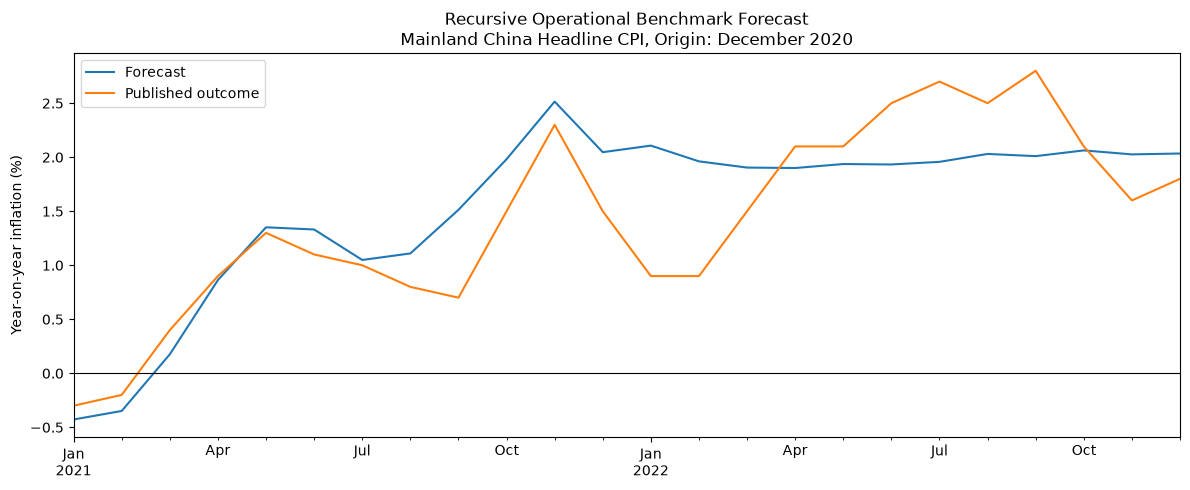

In [6]:
plot_data = headline_forecast.set_index("target_date")[[
    "yoy_forecast",
    "headline_yoy_published",
]].rename(
    columns={
        "yoy_forecast": "Forecast",
        "headline_yoy_published": "Published outcome",
    }
)

ax = plot_data.plot(
    title=(
        "Recursive Operational Benchmark Forecast\n"
        "Mainland China Headline CPI, Origin: December 2020"
    ),
    xlabel="",
    ylabel="Year-on-year inflation (%)",
    figsize=(12, 5),
)
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

## 8. Summarise the illustrative forecast errors

For this one forecast path, mean absolute error and root mean squared error are

$$
\mathrm{MAE}
=
\frac{1}{H}
\sum_{h=1}^{H}
\left|e_{T+h\mid T}\right|,
$$

and

$$
\mathrm{RMSE}
=
\sqrt{
\frac{1}{H}
\sum_{h=1}^{H}
e_{T+h\mid T}^{2}
}.
$$

RMSE gives relatively greater weight to the largest misses. These summary values are useful for checking the demonstration, but they should not be treated as the benchmark's general performance because they come from only one forecast origin.

In [7]:
illustrative_metrics = pd.Series(
    {
        "forecast_origin": FORECAST_ORIGIN,
        "forecast_count": len(headline_forecast),
        "mean_error": headline_forecast["forecast_error"].mean(),
        "mae": headline_forecast["absolute_error"].mean(),
        "rmse": headline_forecast["squared_error"].mean() ** 0.5,
    },
    name="headline_operational_benchmark",
)

display(illustrative_metrics.to_frame("value"))

print(
    f"Illustrative MAE:  {illustrative_metrics['mae']:.3f} percentage points"
)
print(
    f"Illustrative RMSE: {illustrative_metrics['rmse']:.3f} percentage points"
)

,value
forecast_origin,2020-12-01 00:00:00
forecast_count,24
mean_error,-0.105186
mae,0.397397
rmse,0.510438


Illustrative MAE:  0.397 percentage points
Illustrative RMSE: 0.510 percentage points


## 9. Benchmark conclusion and next-stage dependency

This notebook verifies that the operational benchmark:

- produces a complete 24-month sequence of monthly, index-level, and year-on-year forecasts;
- uses a five-year same-calendar-month average rather than a global unconditional average;
- respects the forecast-origin information set;
- recursively incorporates its own earlier forecasts beyond the first year;
- creates forecast errors with an explicit and consistent sign convention.

The benchmark is intentionally simple. It contains no estimated ARMA parameters and no explicit Chinese New Year adjustment. Its value is as a transparent seasonal standard: a more complex model should justify its additional assumptions through better out-of-sample accuracy or reliability.

The later expanding-window evaluation reruns this same procedure at every historical forecast origin and calculates MAE and RMSE on common samples shared with the statistical models. Those pooled evaluations, not the single-origin metrics reported here, determine the benchmark's final comparative performance.

In [8]:
# Export benchmark recursion audit

OUTPUT_TABLES = PROJECT_ROOT / "outputs" / "tables"
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

benchmark_recursion_audit = pd.concat(
    [
        horizon_1_audit.assign(audit_case="horizon_1_observed_inputs"),
        horizon_13_audit.assign(audit_case="horizon_13_recursive_input"),
    ],
    ignore_index=True,
)

audit_columns = [
    "audit_case",
    "horizon",
    "target_date",
    "input_date",
    "input_type",
    "input_value",
]

benchmark_recursion_audit = benchmark_recursion_audit[
    [
        column
        for column in audit_columns
        if column in benchmark_recursion_audit.columns
    ]
]

output_path = (
    OUTPUT_TABLES
    / "02_benchmark_recursion_audit.csv"
)

benchmark_recursion_audit.to_csv(
    output_path,
    index=False,
)

print("Saved:", output_path.relative_to(PROJECT_ROOT))

Saved: outputs/tables/02_benchmark_recursion_audit.csv


In [9]:
# Save illustrative benchmark forecast

OUTPUT_FIGURES = PROJECT_ROOT / "outputs" / "figures"
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

figure_path = (
    OUTPUT_FIGURES
    / "02_benchmark_forecast_example.png"
)

ax.figure.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print("Saved:", figure_path.relative_to(PROJECT_ROOT))
plt.show()

Saved: outputs/figures/02_benchmark_forecast_example.png
